Q1: Modeling and Analyzing Neural Spike Patterns
A. Constructing the Models and Assumptions

I simulated 5 seconds of spike times for three types of neurons. I chose parameters so that all three neurons fire at about the same average speed (~10 spikes per second), so I can compare their patterns fairly.

1. Regular neuron: This model is deterministic (no randomness). It fires at a fixed interval of 0.1 seconds.

2. Irregular neuron: This model is stochastic (random). Each waiting time between spikes is picked randomly from an exponential distribution (rng.exponential) with an average of 0.1 seconds. I chose the exponential distribution because it always gives positive waiting times, with many short gaps and fewer long ones, which fits random firing with no memory of past spikes. I used seed=42 so I get the same results every time I run the notebook.

3. Bursting neuron: This model fires 4 quick spikes in a group (about 0.02 seconds apart) and then waits a longer quiet time (about 0.34 seconds) before the next group. I added small random noise to both waiting times so the bursts are not identical.

To make sure all spike times are valid and in time order, I always add positive waiting times and stop at 5.0 seconds. I also used max() so the random noise never makes an interval zero or negative.

In [ ]:
import numpy as np
# start - 0.1 , stop - 5 , step - 0.1
regular_spikes = np.arange(0.1, 5.01, 0.1)
print("Count:", len(regular_spikes))
print("First 5 spikes:", regular_spikes[:5])    



Count: 50
First 5 spikes: [0.1 0.2 0.3 0.4 0.5]


In [ ]:
# Create a random generator with a fixed seed for reproducible results
rng = np.random.default_rng(42)

spikes = []          # Empty list to store spike times
current_time = 0.0   # Start clock at 0 seconds

while True:
    # Draw a random positive waiting time (mean = 0.1 s), ISI = Inter-Spike Interval
    isi = rng.exponential(scale=0.1)
    current_time += isi  # Move clock forward

    # Stop if we pass the 5-second recording window
    if current_time > 5.0:
        break

    spikes.append(current_time)  # Save valid spike time

# Convert list to NumPy array for easy calculations later
irregular_spikes = np.array(spikes)

print("Count:", len(irregular_spikes))
print("First 5 spikes:", np.round(irregular_spikes[:5], 3))

Count: 60
First 5 spikes: [0.24  0.474 0.713 0.74  0.749]


In [ ]:
# I chose 4 spikes per burst so each group of spikes is easy to see
spikes_per_burst = 4
intra_burst_mean = 0.02  # Short interval within a burst (20 ms)
inter_burst_mean = 0.34  # Long quiet interval between bursts (340 ms)

spikes_burst = []
current_time = 0.05  # Start after t = 0 for consistency with the other neurons and clearer plotting

while current_time <= 5.0:
    # 1. Fire a rapid burst of 4 spikes
    for i in range(spikes_per_burst):
        if current_time > 5.0:
            break
        spikes_burst.append(current_time)
        # Add a short gap only between spikes in the burst (not after the last spike)
        if i < spikes_per_burst - 1:
        # Keep the interval positive (at least 2 ms) even if random noise is negative. 0.002 is for safety
            intra_isi = max(0.002, intra_burst_mean + rng.normal(0, 0.003))
            current_time += intra_isi

    # 2. Add a long quiet interval before the next burst starts
        # Keep the quiet gap between bursts positive (at least 50 ms) even if random noise is negative
    inter_isi = max(0.05, inter_burst_mean + rng.normal(0, 0.015))
    current_time += inter_isi

bursting_spikes = np.array(spikes_burst)

print("Count:", len(bursting_spikes))
print("First 8 spikes:", np.round(bursting_spikes[:8], 3))

Count: 52
First 8 spikes: [0.05  0.073 0.095 0.119 0.456 0.474 0.494 0.514]


B. Investigating the Firing Patterns

To compare the three neurons, I used a spike raster plot (to see the timing over the 5 seconds), and I chose a summary table (mean rate, mean ISI(Inter-Spike Interval), median ISI, SD, CV(SD / Mean)) plus ISI histograms to compare the spread of the waiting times.

1. Spikes over time and what the raster plot shows:
The raster plot clearly shows the timing differences. The regular neuron fires evenly like a clock, the irregular neuron fires at random times with unpredictable gaps, and the bursting neuron fires in tight groups of 4 spikes with quiet gaps between them.

2. What the ISI distributions show:
The ISIs show the waiting times between spikes. In the histograms, the regular neuron has one single bar at 0.1 s. The irregular neuron has many short intervals and fewer long ones (an exponential shape). The bursting neuron has two separate groups: very short intervals (~0.02 s) inside bursts and long intervals (~0.34 s) between bursts.

3. Can mean firing rate alone distinguish them?
No. All three neurons have almost the same mean firing rate (10.0 Hz, 12.0 Hz, and 10.4 Hz), so the average rate alone cannot tell them apart.

4. Additional statistics that help:
The median ISI, standard deviation (SD), and CV (SD / Mean) distinguish the neurons well. The SD shows how spread out the intervals are: 0.000 s for regular, 0.078 s for irregular, and largest (0.134 s) for bursting because it mixes very short and long gaps. The CV gives a clear scale: 0.000 for regular, 0.976 (close to 1) for irregular, and 1.419 (above 1) for bursting. Also, in the bursting neuron, the median ISI (0.021 s) is much smaller than the mean ISI (0.094 s) because most intervals are inside bursts.

In [9]:
import pandas as pd

# Put the 3 spike arrays in a dictionary so I can loop over them easily
neurons = {
    "Regular": regular_spikes,
    "Irregular": irregular_spikes,
    "Bursting": bursting_spikes,
}

summary_rows = []
isis_dict = {}  # Save the ISIs so I can plot them in the next step

for name, spikes in neurons.items():
    isis = np.diff(spikes)  # Calculate time gaps between consecutive spikes
    isis_dict[name] = isis

    mean_isi = np.mean(isis)
    std_isi = np.std(isis)

    summary_rows.append({
        "Neuron": name,
        "Spikes": len(spikes),
        "Mean Rate (Hz)": round(len(spikes) / 5.0, 2),
        "Mean ISI (s)": round(mean_isi, 4),
        "Median ISI (s)": round(np.median(isis), 4),
        "SD ISI (s)": round(std_isi, 4),
        "CV (SD/Mean)": round(std_isi / mean_isi, 3),
    })

summary_df = pd.DataFrame(summary_rows)
summary_df

,Neuron,Spikes,Mean Rate (Hz),Mean ISI (s),Median ISI (s),SD ISI (s),CV (SD/Mean)
0,Regular,50,10.0,0.1000,0.1000,0.0000,0.000
1,Irregular,60,12.0,0.0796,0.0453,0.0777,0.976
2,Bursting,52,10.4,0.0942,0.0210,0.1337,1.419


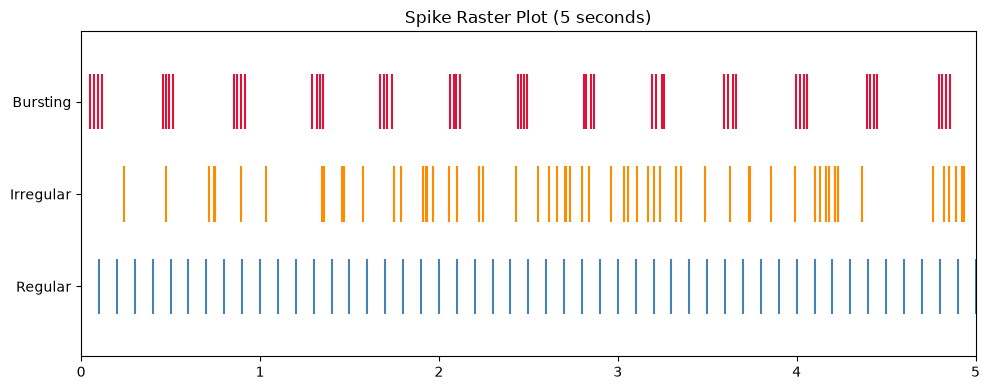

In [11]:
import os
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)  # Create figures folder if it does not exist

fig, ax = plt.subplots(figsize=(10, 4))

# Draw vertical lines for every spike of each neuron on its own row
ax.eventplot(
    [regular_spikes, irregular_spikes, bursting_spikes],
    lineoffsets=[0, 1, 2],  # Place each neuron on its own row (y = 0, 1, 2)
    linelengths=0.6,        # Height of each vertical spike line
    colors=["steelblue", "darkorange", "crimson"],
)

ax.set_yticks([0, 1, 2])
ax.set_yticklabels(["Regular", "Irregular", "Bursting"])
ax.set_xlim(0, 5.0)  # Show the exact 0 to 5 second recording window on the x-axisax.set_xlabel("Time (seconds)")
ax.set_title("Spike Raster Plot (5 seconds)")

plt.tight_layout()  # Adjust spacing so labels do not get cut off
plt.savefig("figures/q1_raster_plot.png", dpi=150)  # Save high-quality image before showing
plt.show()          # Display the plot below this cell

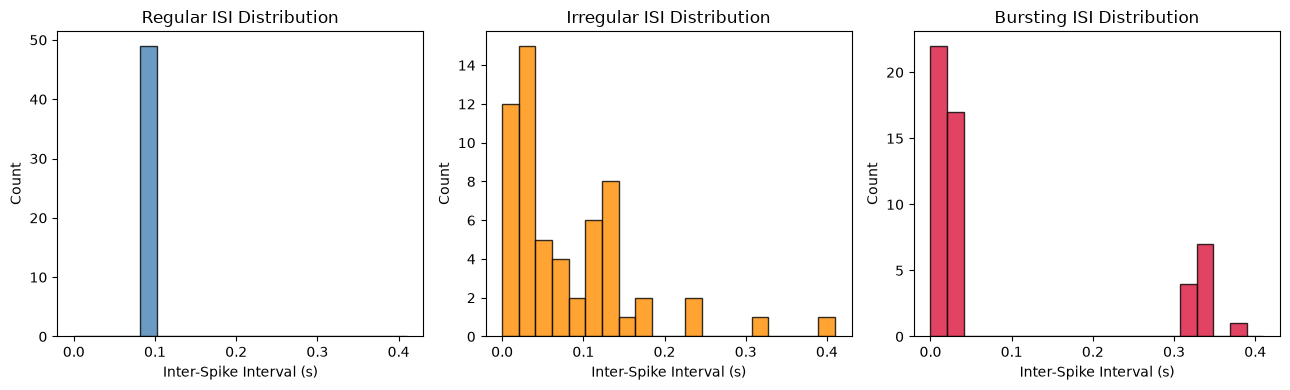

In [13]:
# Create 3 side-by-side plots that share the same x-axis for fair comparison
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True)

# Create 20 equal bins (21 edges) from 0 to 0.41 s so 0.1 s falls inside one bin
bins = np.linspace(0, 0.41, 21)
bins = np.linspace(0, 0.41, 21)
colors = ["steelblue", "darkorange", "crimson"]

# Loop through each subplot, neuron's ISIs, and color together using zip
for ax, (name, isis), color in zip(axes, isis_dict.items(), colors):
    # Plot histogram with black bar outlines and slight transparency
    ax.hist(isis, bins=bins, color=color, edgecolor="black", alpha=0.8)
    ax.set_title(f"{name} ISI Distribution")  # Set title for this neuron
    ax.set_xlabel("Inter-Spike Interval (s)")  # Label x-axis
    ax.set_ylabel("Count")                     # Label y-axis

plt.tight_layout()  # Adjust spacing so labels do not overlap
plt.savefig("figures/q1_isi_histograms.png", dpi=150)  # Save image for submission
plt.show()

--------C---------

In [14]:
# Check 1 (Temporal behavior):
# Verify that all spikes are within (0, 5.0] s, all ISIs are positive,
# and the regular neuron has constant 0.1 s intervals.

for name, spikes in neurons.items():
    isis = np.diff(spikes)

    in_window = np.all((spikes > 0) & (spikes <= 5.0))  # All spikes between 0 and 5 s?
    positive_isis = np.all(isis > 0)  # All intervals strictly positive?

    print(f"{name}: inside (0, 5.0]s = {in_window}, all ISIs > 0 = {positive_isis}")

# Check that all intervals of the regular neuron are equal to 0.1 s
regular_constant = np.allclose(np.diff(regular_spikes), 0.1)
print("Regular neuron has constant 0.1 s intervals:", regular_constant)

Regular: inside (0, 5.0]s = True, all ISIs > 0 = True
Irregular: inside (0, 5.0]s = True, all ISIs > 0 = True
Bursting: inside (0, 5.0]s = True, all ISIs > 0 = True
Regular neuron has constant 0.1 s intervals: True


In [ ]:
#########need to check########
# Check 2 (Statistical properties - Irregular neuron):
# Test that in the irregular neuron (which uses an exponential distribution),
# increasing the scale parameter increases both Mean ISI and SD ISI, while CV stays close to 1.0.

def run_irregular(duration, scale, seed=42):
    # Helper function using the exact same logic from Part A
    rng_test = np.random.default_rng(seed)
    spikes_test = []
    t = 0.0
    while True:
        t += rng_test.exponential(scale=scale)
        if t > duration:
            break
        spikes_test.append(t)
    return np.array(spikes_test)

# Test 3 different scale values over 200 seconds for stable statistics
for scale_val in [0.05, 0.10, 0.20]:
    test_spikes = run_irregular(duration=200.0, scale=scale_val, seed=42)
    test_isis = np.diff(test_spikes)
    mean_val = np.mean(test_isis)
    sd_val = np.std(test_isis)
    cv_val = sd_val / mean_val
    print(f"scale={scale_val:.2f} -> Mean ISI={mean_val:.3f}s, SD={sd_val:.3f}s, CV={cv_val:.2f}")